# NoiseSOM
Noise-aware broadband SOM trained on fixed LSST-like CFHT u/HSC grizy photometry.
Training spectra calibrate a redshift PDF in each cell. This is a single broadband
SOM, not the full deep-to-wide SOMPZ pipeline.

Use the fixed configuration selected by the main comparison: 32 × 32 cells,
60,000 updates, smoothing width 0.01 in ln(1 + z), and five global pseudo-counts.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

from pzflow.utils import PDFSampler

# noiseSOM
sys.path.insert(0, '../bin')
import NoiseSOM as noise

In [2]:
plt.rcParams.update(
    {
        'font.family': 'serif',
        'font.size': 11,
        'axes.linewidth': 1.5,
        'xtick.major.size': 5,
        'ytick.major.size': 5,
        'xtick.major.width': 1.5,
        'ytick.major.width': 1.5,
        'legend.frameon': False,
    }
)

In [3]:
seed = 20261024
side = 32
n_updates = 60000
bandwidth = 0.01
alpha = 5.0

## 2. Load the data and preserve the spatial split
Fluxes and errors are in microJy, ordered u, g, r, i, z, y, with shape (N, 6).
Use the fixed degraded photometry without adding noise. The split is spatial:
0 = training, 1 = validation, 2 = test. Only training spectra populate cell PDFs.

In [4]:
keys = ['id', 'flux', 'fluxerr', 'zspec', 'split', 'imag', 'cell']
with np.load('../data/parent.npz') as f:
    data = {key: f[key] for key in keys}

flux = data['flux'].astype(float)
err = data['fluxerr'].astype(float)
zspec = data['zspec']
train, valid, test = [
    np.flatnonzero((data['split'] == split) & np.isfinite(zspec)) for split in range(3)
]

assert flux.shape == err.shape == (len(data['id']), 6)
assert len(np.unique(data['id'])) == len(data['id'])
assert np.isfinite(flux).all() and np.isfinite(err).all() and (err > 0).all()
assert np.all((zspec[train] > 0) & (zspec[train] <= 10))
for a, b in [(train, valid), (train, test), (valid, test)]:
    assert not np.intersect1d(data['cell'][a], data['cell'][b]).size

for name, rows in zip(['Training', 'Validation', 'Test'], [train, valid, test]):
    print(f'{name}: {len(rows):,} galaxies')

Training: 22,604 galaxies
Validation: 4,803 galaxies
Test: 5,083 galaxies


## 3. Train the map on broadband fluxes and errors
Sample training rows with replacement and fix both random seeds. The metric
uses flux uncertainties directly, with a 0.02 fractional-error floor during
training. Classification uses the supplied errors. Redshift labels do not
enter the map fit.

In [5]:
metric = noise.AsinhMetric(lnScaleSigma=0.4, lnScaleStep=0.03)

rows = np.random.default_rng(seed).integers(len(train), size=n_updates)
np.random.seed(seed)
som = noise.NoiseSOM(
    metric,
    flux[train][rows],
    err[train][rows],
    learning=noise.hFunc(n_updates, sigma=(30.0, 1.0)),
    shape=(side, side),
    wrap=False,
    logF=True,
    initialize='sample',
    minError=0.02,
)
weights = som.weights
assert weights.shape == (side * side, 6)
assert np.isfinite(weights).all() and (weights > 0).all()
print(f'Trained {side} x {side} cells')

Training 0
Training 10000
Training 20000
Training 30000
Training 40000
Training 50000
Trained 32 x 32 cells


## 4. Assign training galaxies and count their redshifts
Choose the cell with the smallest noise-aware distance in bounded-memory batches.
Count training spectra in 2,000 uniform bins of t = ln(1 + z), spanning 0 ≤ z ≤ 10.

In [6]:
def assign(flux, errors, weights, metric):
    ''' Published noise-aware assignment, including negative-flux measurements. '''
    cells = []
    # Match the reference classifier's ten-target chunks and supplied errors.
    # The upstream metric caps exp-based weights; suppress harmless overflow
    # warnings from values subsequently capped at 1000, without changing values.
    with np.errstate(over='ignore'):
        for start in range(0, len(flux), 10):
            cells.append(
                metric(weights, flux[start : start + 10], errors[start : start + 10]).argmin(0)
            )
    return np.concatenate(cells)

train_cell = assign(flux[train], err[train], weights, metric)

edges = np.linspace(0, np.log(11), 2001)
grid = np.expm1(np.r_[0, (edges[1:] + edges[:-1]) / 2, edges[-1]])
zbin = np.clip(np.searchsorted(edges, np.log1p(zspec[train])) - 1, 0, len(edges) - 2)
hist = np.zeros((len(weights), len(edges) - 1))
np.add.at(hist, (train_cell, zbin), 1)

count = hist.sum(axis=1)
global_hist = hist.sum(axis=0) / hist.sum()
assert count.sum() == len(train)
print(f'Occupied cells: {(count > 0).sum():,} / {len(weights):,}')

Occupied cells: 1,022 / 1,024


## 5. Turn cell histograms into redshift PDFs
Empty cells borrow the nearest populated prototype's histogram. Add `alpha`
global training pseudo-counts, smooth in ln(1 + z), and divide by (1 + z) to
obtain a density in z. `PDFSampler` normalizes the density and integrates its CDF.

In [7]:
filled = np.flatnonzero(count > 0)
empty = np.flatnonzero(count == 0)
fallback = np.arange(len(weights))
prototype_err = np.median(err[train], axis=0)
if len(empty):
    nearest = assign(
        weights[empty],
        np.broadcast_to(prototype_err, weights[empty].shape),
        weights[filled],
        metric,
    )
    fallback[empty] = filled[nearest]

hist_pdf = hist[fallback] + alpha * global_hist
hist_pdf = gaussian_filter1d(hist_pdf, bandwidth / np.diff(edges)[0], axis=1, mode='reflect')
hist_pdf /= hist_pdf.sum(axis=1)[:, None]
pdf = np.pad(hist_pdf, ((0, 0), (1, 1)), mode='edge') / (1 + grid)[None, :]
sampler = PDFSampler(grid, pdf)
assert np.allclose(np.trapezoid(sampler.p, grid, axis=1), 1, atol=1e-6)
assert np.all(np.diff(sampler.c, axis=1) >= -1e-7)
assert np.allclose(sampler.c[:, -1], 1)

Inspect the training occupancy and the mean redshift of each cell. The redshift
map comes from the training labels, not from test galaxies. Empty cells use the
fallback PDFs constructed above.

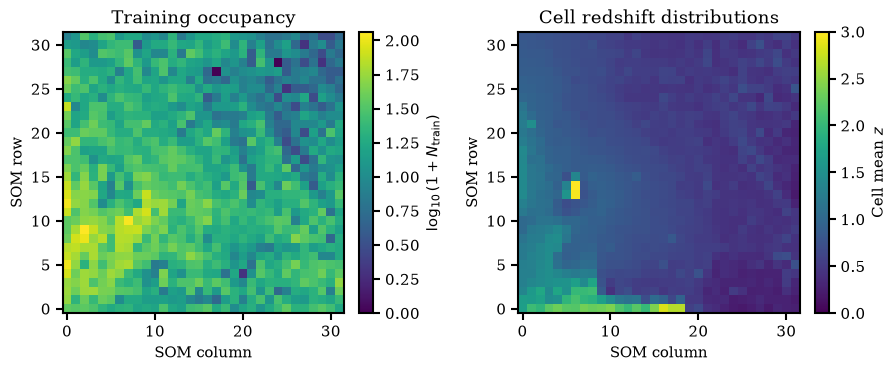

In [8]:
mean_z = np.trapezoid(sampler.p * grid[None, :], grid, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), constrained_layout=True)
im = axes[0].imshow(np.log10(1 + count.reshape(side, side)), origin='lower')
fig.colorbar(im, ax=axes[0], label=r'$\log_{10}(1 + N_{\mathrm{train}})$')
im = axes[1].imshow(mean_z.reshape(side, side), origin='lower', vmin=0, vmax=3)
fig.colorbar(im, ax=axes[1], label=r'Cell mean $z$')
for ax, title in zip(axes, ['Training occupancy', 'Cell redshift distributions']):
    ax.set(xlabel='SOM column', ylabel='SOM row', title=title)
plt.show()

## 6. Evaluate validation density
Use a fixed subset of up to 4,096 validation galaxies. Settings were selected
in the main comparison; test labels do not select hyperparameters.

In [9]:
def density_at(sampler, z, cells):
    j = np.clip(np.searchsorted(sampler.grid, z) - 1, 0, len(sampler.grid) - 2)
    w = (z - sampler.grid[j]) / np.diff(sampler.grid)[j]
    return (1 - w) * sampler.p[cells, j] + w * sampler.p[cells, j + 1]

vi = np.random.default_rng(seed).choice(valid, min(len(valid), 4096), replace=False)
valid_cell = assign(flux[vi], err[vi], weights, metric)
valid_nll = -np.log(np.maximum(density_at(sampler, zspec[vi], valid_cell), 1e-12)).mean()
print(f'Validation NLL: {valid_nll:.4f}')

Validation NLL: -1.2978


## 7. Apply the map to test photometry
Assign each spectroscopic test galaxy using only fluxes and uncertainties.
Its prediction is the PDF of its assigned cell. Quantiles are 2.5%, 16%, 50%,
84%, and 97.5%; redshift labels enter only the evaluation below.

In [10]:
test_cell = assign(flux[test], err[test], weights, metric)
levels = np.array([0.025, 0.16, 0.5, 0.84, 0.975])
cell_quantiles = np.array([np.interp(levels, cdf, grid) for cdf in sampler.c])
q = cell_quantiles[test_cell]

assert np.isfinite(q).all() and np.all(np.diff(q, axis=1) >= 0)
print(f'Predicted {len(test_cell):,} test galaxies')
print(f'Assigned to an empty training cell: {np.mean(count[test_cell] == 0):.2%}')

Predicted 5,083 test galaxies
Assigned to an empty training cell: 0.02%


## 8. Evaluate against held-out spectroscopy

In [11]:
ztest = zspec[test]
pit = sampler.pit(ztest, test_cell)
nll = -np.log(np.maximum(density_at(sampler, ztest, test_cell), 1e-12))

[(0.0, 5.0),
 (0.0, 5.0),
 Text(0.5, 0, '$z_{\\mathrm{spec}}$'),
 Text(0, 0.5, 'Median $z$')]

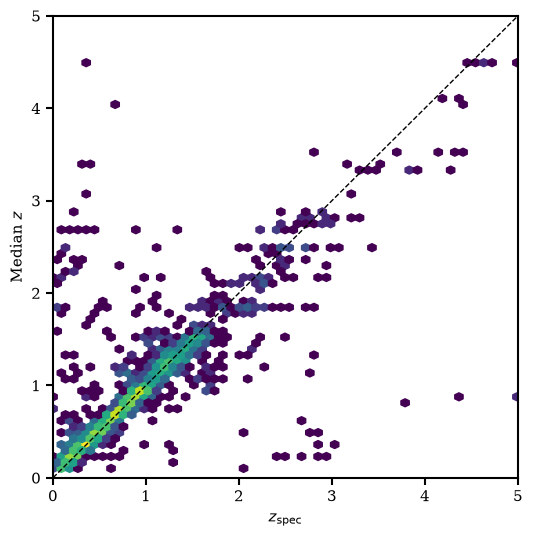

In [12]:
fig = plt.figure(figsize=(6,6))
sub = fig.add_subplot(111)
sub.hexbin(ztest, q[:, 2], gridsize=60, bins='log', mincnt=1, cmap='viridis')
sub.plot([0, 5], [0, 5], 'k--', lw=1)
sub.set(xlim=(0, 5), ylim=(0, 5), xlabel=r'$z_{\mathrm{spec}}$', ylabel=r'Median $z$')

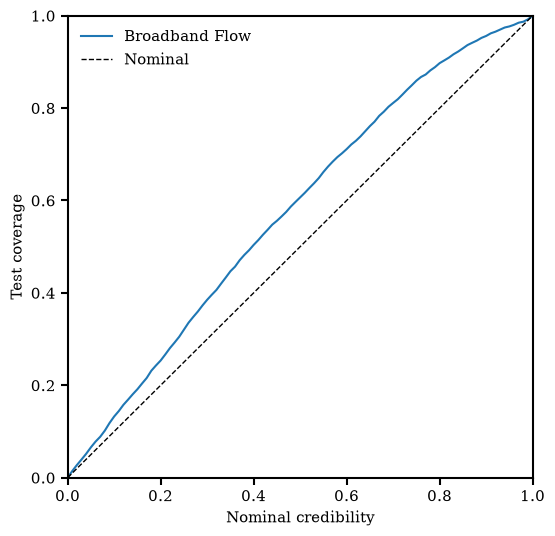

In [13]:
credibility = np.linspace(0, 1, 101)
rank = np.abs(2 * pit - 1)
curve = np.array([(rank <= level).mean() for level in credibility])
curve[0], curve[-1] = 0, 1

fig = plt.figure(figsize=(6,6))
sub = fig.add_subplot(111)
sub.plot(credibility, curve, label='Broadband Flow')
sub.plot([0, 1], [0, 1], 'k--', lw=1, label='Nominal')
sub.set(xlim=(0, 1), ylim=(0, 1), xlabel='Nominal credibility', ylabel='Test coverage')
sub.legend()
plt.show()

Example test PDFs below span the test sample's magnitude distribution. The
vertical line is the spectroscopic redshift, shown for evaluation only.

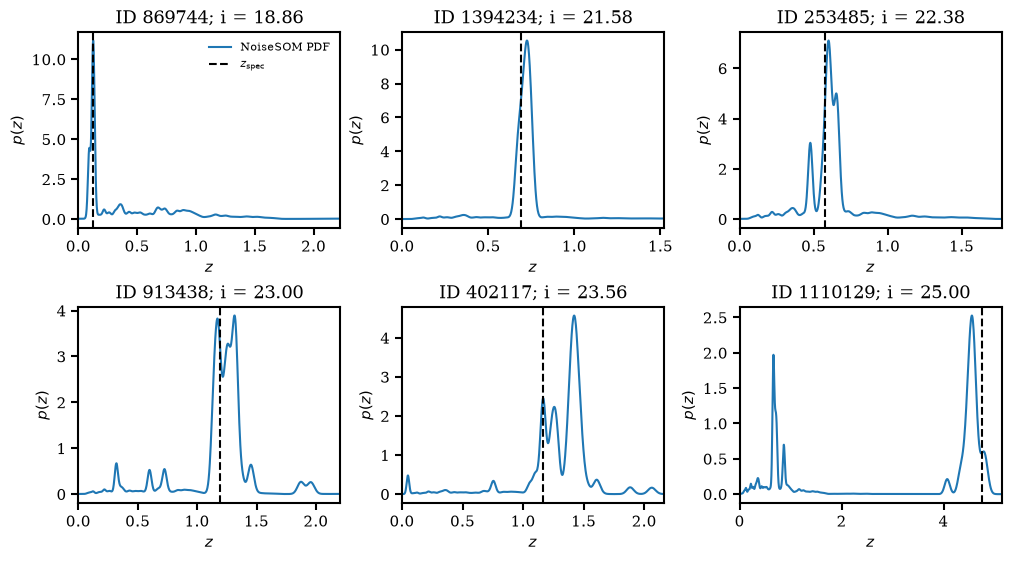

In [14]:
order = np.argsort(data['imag'][test])
examples = order[np.linspace(0, len(order) - 1, 6, dtype=int)]
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), constrained_layout=True)
for ax, j in zip(axes.flat, examples):
    ax.plot(grid, sampler.p[test_cell[j]], label='NoiseSOM PDF')
    ax.axvline(ztest[j], color='k', ls='--', label=r'$z_{\mathrm{spec}}$')
    right = min(10, max(q[j, 4], ztest[j]) + 0.3)
    ax.set(xlim=(0, right), xlabel=r'$z$', ylabel=r'$p(z)$')
    ax.set_title(f'ID {data["id"][test[j]]}; i = {data["imag"][test[j]]:.2f}')
axes.flat[0].legend(fontsize=8)
plt.show()

## 9. Save the map and its predictions

In [15]:
np.savez_compressed(
    '../data/noisesom.npz',
    weights=weights,
    grid=grid,
    pdf=sampler.p,
    count=count,
    fallback=fallback,
    seed=seed,
    bandwidth=bandwidth,
    alpha=alpha,
)

prediction = {key: data[key][test] for key in ['id', 'zspec', 'imag', 'flux', 'fluxerr']}
prediction.update(quantiles=q, pit=pit, nll=nll, som_cell=test_cell)
np.savez_compressed('../data/noisesom_test_predictions.npz', **prediction)